2.11.0+cu128
Using device: cuda
Epoch [1/5], Loss: 0.3178, Train Accuracy: 96.42%, Test Accuracy: 96.61%
Epoch [2/5], Loss: 0.0883, Train Accuracy: 97.67%, Test Accuracy: 97.86%
Epoch [3/5], Loss: 0.0643, Train Accuracy: 98.38%, Test Accuracy: 98.28%
Epoch [4/5], Loss: 0.0481, Train Accuracy: 98.60%, Test Accuracy: 98.31%
Epoch [5/5], Loss: 0.0412, Train Accuracy: 98.93%, Test Accuracy: 98.74%


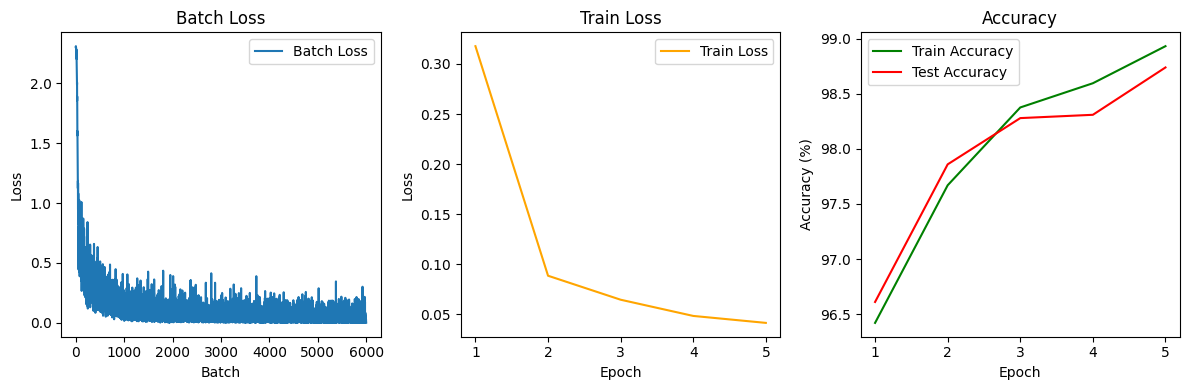

In [2]:
import torch
print(torch.__version__)
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool(x)
        x = torch.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(-1, 16 * 5 * 5)  # Flatten the tensor
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x    
    
    
transform = transforms.Compose([
    transforms.Pad(padding=2),
    transforms.ToTensor(),
])

batch_size = 50
data_root = './data'

trainset = torchvision.datasets.MNIST(root=data_root, train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root=data_root, train=False, download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

batch_losses = []
train_losses = []
train_accuracies = []
test_accuracies = []

def accuracy(loader):
    model.eval() # Ensure model is in eval mode during evaluation
    correct, total = 0, 0
    with torch.no_grad():
        for data, labels in loader:
            data, labels = data.to(device), labels.to(device)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

epochs = 5

for epoch in range(epochs):
    model.train()  # Set the model to training mode
    running_loss = 0.0
    for i, (data, labels) in enumerate(trainloader):
        data, labels = data.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        batch_losses.append(loss.item())
    
    train_loss = running_loss / len(trainloader)
    train_losses.append(train_loss)
    
    train_acc = accuracy(trainloader)
    test_acc = accuracy(testloader)
    
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    
    print(f"Epoch [{epoch + 1}/{epochs}], Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.2f}%, Test Accuracy: {test_acc:.2f}%")

# Plotting code remains the same, but now it will display 5 points connected by lines!
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(batch_losses, label='Batch Loss')
plt.title('Batch Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss', color='orange')
plt.title('Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(range(1, epochs + 1), train_accuracies, label='Train Accuracy', color='green')
plt.plot(range(1, epochs + 1), test_accuracies, label='Test Accuracy', color='red')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()